In [2]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset column names
columns = [
    'ID', 'RI', 'Na', 'Mg', 'Al',
    'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type'
]

# Load dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"

df = pd.read_csv(url, header=None, names=columns)

# Remove ID because it is only an identification column
df = df.drop(columns=['ID'])

print("Dataset loaded successfully!")

Dataset loaded successfully!


# 2. Understand the dataset

In [3]:
# Display first 5 rows
print("First 5 rows:")
display(df.head())

# Display last 5 rows
print("Last 5 rows:")
display(df.tail())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical description
print("\nStatistical Description:")
display(df.describe())

First 5 rows:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


Last 5 rows:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
209,1.51623,14.14,0.0,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.0,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.0,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.0,1.94,73.61,0.00,8.48,1.57,0.0,7
213,1.51711,14.23,0.0,2.08,73.36,0.00,8.62,1.67,0.0,7


Dataset Shape: (214, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB

Statistical Description:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


# 3. Check missing values and duplicates

In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Display duplicate records
display(df[df.duplicated()])

Missing Values:
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
1


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
39,1.52213,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1


# Question 1: How many samples are present for each glass type?

In [5]:
glass_counts = df['Type'].value_counts().sort_index()

print("Number of samples for each glass type:")
print(glass_counts)

Number of samples for each glass type:
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


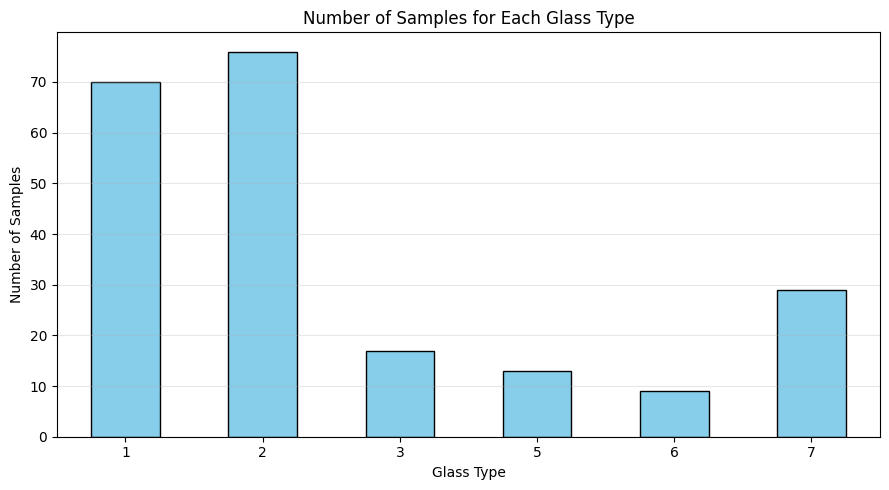

In [6]:
plt.figure(figsize=(9, 5))

glass_counts.plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Number of Samples for Each Glass Type')
plt.xlabel('Glass Type')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Question 2: Calculate the average and range of refractive index, sodium, magnesium and aluminium.


In [7]:
# Selected chemical columns
selected_columns = ['RI', 'Na', 'Mg', 'Al']

# Convert selected columns into a NumPy array
chemical_array = df[selected_columns].to_numpy()

# Calculate statistics using NumPy
print("Overall Chemical Statistics:\n")

for i, column in enumerate(selected_columns):

    values = chemical_array[:, i]

    mean_value = np.mean(values)
    median_value = np.median(values)
    min_value = np.min(values)
    max_value = np.max(values)
    range_value = max_value - min_value

    print(f"Chemical: {column}")
    print("Mean:", round(mean_value, 4))
    print("Median:", round(median_value, 4))
    print("Minimum:", round(min_value, 4))
    print("Maximum:", round(max_value, 4))
    print("Range:", round(range_value, 4))
    print("-" * 35)

Overall Chemical Statistics:

Chemical: RI
Mean: 1.5184
Median: 1.5177
Minimum: 1.5112
Maximum: 1.5339
Range: 0.0228
-----------------------------------
Chemical: Na
Mean: 13.4079
Median: 13.3
Minimum: 10.73
Maximum: 17.38
Range: 6.65
-----------------------------------
Chemical: Mg
Mean: 2.6845
Median: 3.48
Minimum: 0.0
Maximum: 4.49
Range: 4.49
-----------------------------------
Chemical: Al
Mean: 1.4449
Median: 1.36
Minimum: 0.29
Maximum: 3.5
Range: 3.21
-----------------------------------


#  Question 3: Which glass type has the highest average magnesium value?

In [8]:
# Calculate average magnesium for each glass type
mg_average = df.groupby('Type')['Mg'].mean()

print("Average Magnesium by Glass Type:")
print(mg_average)

# Find the glass type with the highest average magnesium
highest_mg_type = mg_average.idxmax()
highest_mg_value = mg_average.max()

print("\nGlass type with highest average magnesium:")
print("Glass Type:", highest_mg_type)
print("Average Magnesium:", round(highest_mg_value, 4))

Average Magnesium by Glass Type:
Type
1    3.552429
2    3.002105
3    3.543529
5    0.773846
6    1.305556
7    0.538276
Name: Mg, dtype: float64

Glass type with highest average magnesium:
Glass Type: 1
Average Magnesium: 3.5524


# Question 4: Which 10 samples have the highest sodium values?

In [9]:
# Sort sodium values in descending order
top_10_sodium = df.sort_values(
    by='Na',
    ascending=False
).head(10)

print("Top 10 Samples with Highest Sodium Values:")

display(top_10_sodium[['Type', 'Na', 'RI', 'Mg', 'Al']])

Top 10 Samples with Highest Sodium Values:


,Type,Na,RI,Mg,Al
184,6,17.38,1.51115,0.00,0.34
189,7,15.79,1.52365,1.83,1.31
200,7,15.15,1.51508,0.00,2.25
199,7,15.01,1.51609,0.00,2.51
181,6,14.99,1.51888,0.78,1.74
205,7,14.95,1.51732,0.00,1.80
204,7,14.95,1.51617,0.00,2.27
206,7,14.94,1.51645,0.00,1.87
210,7,14.92,1.51685,0.00,1.99
70,2,14.86,1.51574,3.67,1.74


# Question 6: Compare the average chemical values between glass.

In [10]:
# Calculate average chemical composition by glass type
chemical_comparison = df.groupby('Type')[
    ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
].mean()

print("Average Chemical Composition by Glass Type:")

display(chemical_comparison.round(4))

Average Chemical Composition by Glass Type:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
Type,,,,,,,,,
1,1.5187,13.2423,3.5524,1.1639,72.6191,0.4474,8.7973,0.0127,0.0570
2,1.5186,13.1117,3.0021,1.4082,72.5980,0.5211,9.0737,0.0503,0.0797
3,1.5180,13.4371,3.5435,1.2012,72.4047,0.4065,8.7829,0.0088,0.0571
5,1.5189,12.8277,0.7738,2.0338,72.3662,1.4700,10.1238,0.1877,0.0608
6,1.5175,14.6467,1.3056,1.3667,73.2067,0.0000,9.3567,0.0000,0.0000
7,1.5171,14.4421,0.5383,2.1228,72.9659,0.3252,8.4914,1.0400,0.0134


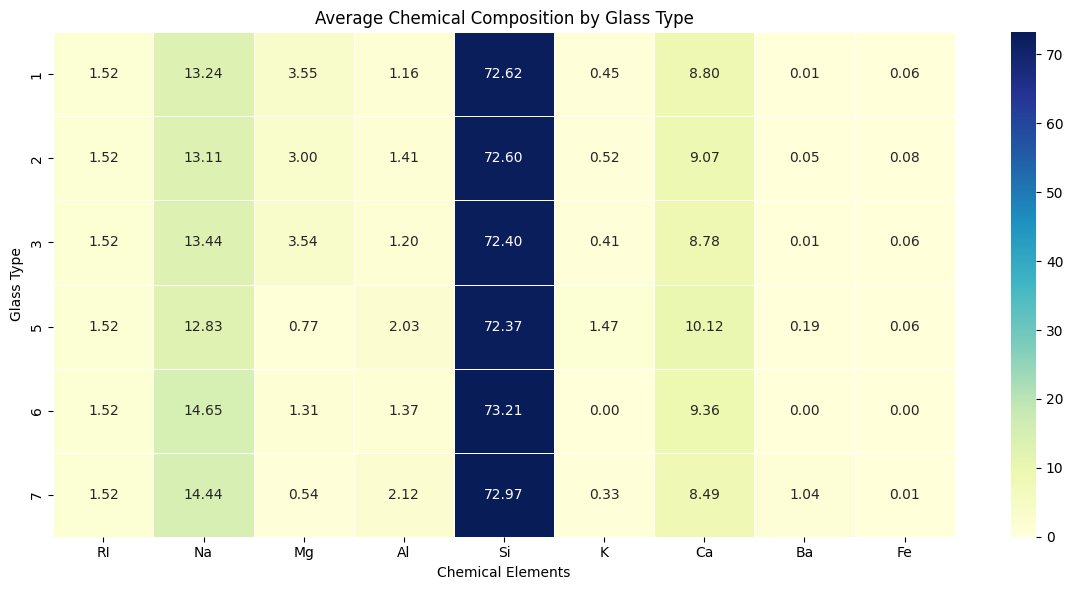

In [11]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    chemical_comparison,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Average Chemical Composition by Glass Type')
plt.xlabel('Chemical Elements')
plt.ylabel('Glass Type')

plt.tight_layout()
plt.show()

9. Create a histogram

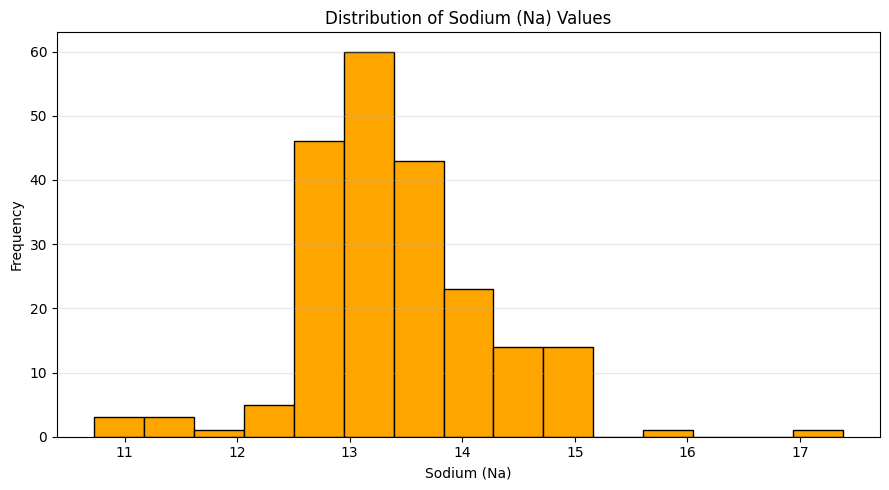

In [12]:
plt.figure(figsize=(9, 5))

plt.hist(
    df['Na'],
    bins=15,
    color='orange',
    edgecolor='black'
)

plt.title('Distribution of Sodium (Na) Values')
plt.xlabel('Sodium (Na)')
plt.ylabel('Frequency')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

10. Write three observations

In [13]:
# Observation 1: Most common glass type
common_type = glass_counts.idxmax()
common_count = glass_counts.max()

# Observation 2: Highest average magnesium
mg_type = mg_average.idxmax()
mg_value = mg_average.max()

# Observation 3: Highest average sodium
na_average = df.groupby('Type')['Na'].mean()
na_type = na_average.idxmax()
na_value = na_average.max()

print("THREE OBSERVATIONS\n")

print(
    f"1. Glass type {common_type} has the highest "
    f"number of samples, with {common_count} samples."
)

print(
    f"2. Glass type {mg_type} has the highest average "
    f"magnesium value of {mg_value:.4f}."
)

print(
    f"3. Glass type {na_type} has the highest average "
    f"sodium value of {na_value:.4f}."
)

THREE OBSERVATIONS

1. Glass type 2 has the highest number of samples, with 76 samples.
2. Glass type 1 has the highest average magnesium value of 3.5524.
3. Glass type 6 has the highest average sodium value of 14.6467.
